In [1]:
# imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path 
from skimage import io
from tqdm import tqdm
import torch
from pathlib import Path
from glob import glob
import anndata as ad
import scanpy as sc
import seaborn as sns
import awkward as ak

# Make sure seed is same in all frameworks
seed = 101
torch.manual_seed(seed)
import random
random.seed(seed)
np.random.seed(seed)

%load_ext autoreload
%autoreload 2

In [2]:
# Set src files on path
import sys
sys.path.insert(0, './make_paper_figures/src/')

In [4]:
from plotting import get_uneven_subplots

In [161]:
import json
with open(base_dir / "gene_map.json", 'r') as f:
    gene_panel = json.load(f)

In [162]:
gene_panel = [el for el in gene_panel.keys() if not any(substring in el for substring in ("Unassigned", "NegControl"))]

## Utility functions specifically for these custom AnnData objects

In [5]:
from adata_utils import convertRecordToDf, decodeSubcellEmbedding, getAllDetectedTranscripts, getXYOfSingleCell, reshape_and_filter_anndata_with_index_and_mapping
from plotting import plotFullDataPoint

### Data reading

In [ ]:
base_dir = Path("/path/to/output/from/raw_spatial_data_processing/")

In [6]:
subcellspace = torch.load("./SubCellSpace")

In [20]:
single_cell_adata = ad.read_h5ad(base_dir / "adata_subcell.h5ad")

/mnt/data/miniconda3/envs/cvae_david3/lib/python3.8/site-packages/anndata/_core/aligned_mapping.py:54: ExperimentalFeatureWarning: Support for Awkward Arrays is currently experimental. Behavior may change in the future. Please report any issues you may encounter!
  warnings.warn(


In [74]:
single_cell_adata

AnnData object with n_obs × n_vars = 154296 × 541
    obs: 'name', 'tile_nr', 'local_row', 'local_col', 'cell_id', 'global_row', 'global_col', 'cell_size'
    var: 'gene_name', 'gene_label'
    uns: 'measured_df'
    obsm: 'cell_mask', 'dapi_mask', 'detected_transcripts'
    layers: 'random_subcell_embedding', 'subcell_embedding'

In [19]:
adata = reshape_and_filter_anndata_with_index_and_mapping(single_cell_adata)

In [21]:
random_adata = reshape_and_filter_anndata_with_index_and_mapping(single_cell_adata, layer="random_subcell_embedding")

# Make shuffled versions of all your observations to do statistical testing

In [7]:
from shuffle import shuffle_all_gene_expression, add_shuffled_embedding

In [298]:
single_cell_adata = shuffle_all_gene_expression(single_cell_adata)




  1%|▉                                                                                                                                  | 1160/154296 [00:11<26:11, 97.47it/s]

KeyboardInterrupt



In [38]:
single_cell_adata = add_shuffled_embedding(single_cell_adata, subcellspace)


In [42]:
single_cell_adata.write_h5ad(base_dir / "adata_subcell_including_randomized.h5ad", compression="gzip")

In [147]:
random_adata = reshape_and_filter_anndata_with_index_and_mapping(single_cell_adata, layer="random_subcell_embedding")

# Classify genes for pattern presence

In [9]:
from classifiers import classify_all_genes

In [11]:
import pickle
path = './classifiers/rf_pattern_nonpattern.pkl'
with open(path, 'rb') as p:
    classifier = pickle.load(p)

In [ ]:
z = adata.obs['gene_name'].value_counts() 

z1 = z.to_dict() #converts to dictionary

adata.obs['n_obs'] = adata.obs['gene_name'].map(z1) 
random_adata.obs['n_obs'] = random_adata.obs['gene_name'].map(z1) 

In [10]:
# take only data of genes with enough obs to make statistic call
tmp_adata = adata[adata.obs["n_obs"] >= 8]
tmp_random_adata = random_adata[random_adata.obs["n_obs"] >= 8]

NameError: name 'adata' is not defined

In [126]:
genes_to_classify = list(tmp_adata.obs["gene_name"].unique())

In [127]:
assert all(adata.obs.index ==  random_adata.obs.index)

In [ ]:
medium_threshold = 0.03
stringent_threshold = 0.06

In [132]:
result_df = classify_all_genes(tmp_adata, classifier, tmp_random_adata, earth_dist_threshold= stringent_threshold, random_seed=seed, store_adata=True)

100%|████████████████████████████████████████████████████████████████████████████████████████████████| 264/264 [02:10<00:00,  2.03it/s]
/home/luna.kuleuven.be/u0147891/SubCellSpace/make_paper_figures/src/classifiers.py:130: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs["earth_dist"] = dist_col


In [179]:
cols_of_interest = ["gene_name", "true_random", "earth_dist", "pval","bonferonni_pval", "passes","passes_earth_thresh", "total_obs_avail", "apex_assigned"]

In [273]:
result_df[cols_of_interest]

,gene_name,true_random,earth_dist,pval,n_obs,bonferonni_pval
0,AASS,False,0.039846,1.690722e-05,1000,4.463506e-03
1,ABHD4,False,0.041924,5.256378e-01,27,1.387684e+02
2,ACER3,False,0.103109,6.028129e-01,21,1.591426e+02
3,ADAM9,False,0.021734,7.761108e-02,1000,2.048933e+01
4,AGO3,False,0.046355,3.270380e-02,333,8.633803e+00
...,...,...,...,...,...,...
259,ZNF609,False,0.008418,6.101665e-01,1000,1.610839e+02
260,ZNF616,False,0.040050,8.125385e-02,340,2.145102e+01
261,ZNF621,False,0.109837,8.661445e-23,1000,2.286622e-20
262,ZNHIT3,True,0.045791,6.669830e-07,1000,1.760835e-04


In [944]:
# these are all genes that show significant patterns
passes_df = result_df[result_df["final_class"] != "random"]
passes_df.index = list(range(len(passes_df)))

0it [00:00, ?it/s]/mnt/data/miniconda3/envs/cvae_david3/lib/python3.8/site-packages/anndata/_core/anndata.py:1838: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/mnt/data/miniconda3/envs/cvae_david3/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


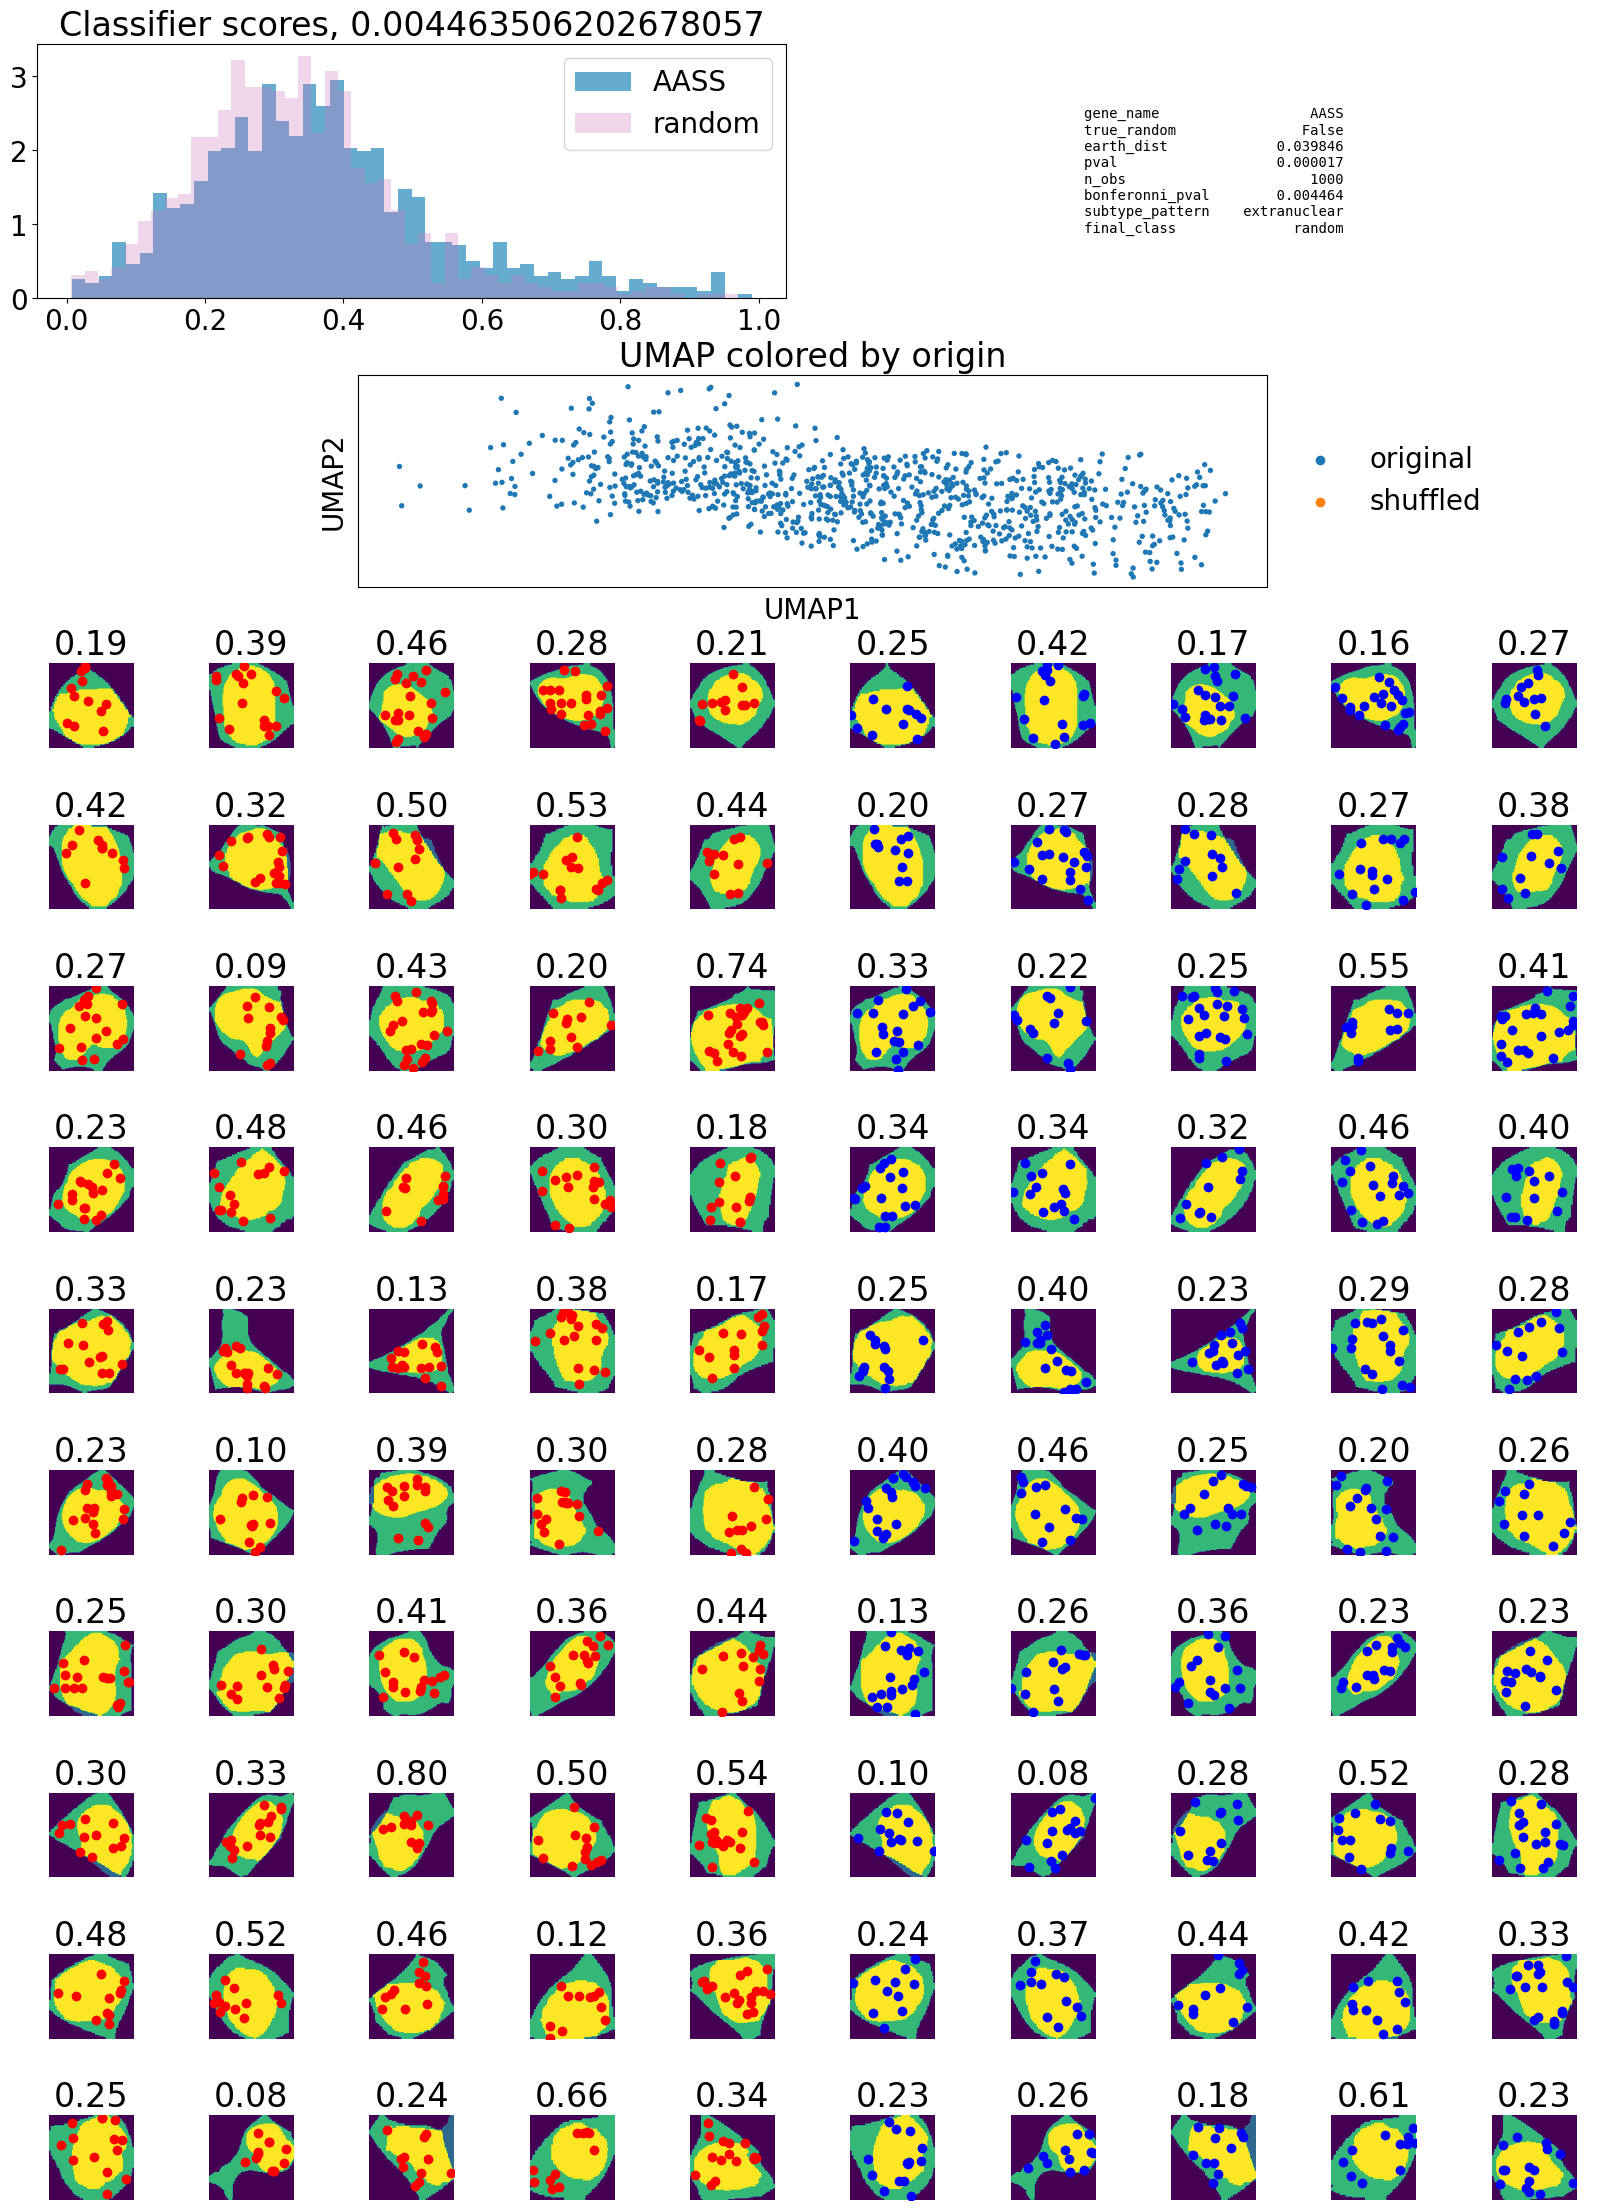

0it [00:05, ?it/s]


In [484]:
# This block plots the 100 most patterned observations of each genein your dataset

plt.rcParams["figure.figsize"] = [20, 10]
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import math

out_base_dir = Path("/fill/in/out/dir")
out_base_dir.mkdir(exist_ok=True)
for tmp_row in tqdm(passes_df.itertuples()):

    # Scores + annotation
    pattern_score = list(tmp_row.pattern.obs["classifier_proba"])
    control_score = list(tmp_row.control.obs["classifier_proba"])
    row_text = result_df[cols_of_interest].loc[tmp_row.Index].to_string()
    tmp_row.control.obs["gene_name"] = "random"

    # Set up subsampled grids
    n_cols = 5
    n_max = 50

    # Subsample pattern
    if len(tmp_row.pattern) > n_max:
        pattern_subsampled = sc.pp.subsample(tmp_row.pattern, n_obs=n_max, random_state=seed, copy=True)
    else:
        pattern_subsampled = tmp_row.pattern.copy()

    # Subsample control
    if len(tmp_row.control) > n_max:
        control_subsampled = sc.pp.subsample(tmp_row.control, n_obs=n_max, random_state=seed, copy=True)
    else:
        control_subsampled = tmp_row.control.copy()

    n_pat = len(pattern_subsampled)
    n_con = len(control_subsampled)
    n_pat_rows = math.ceil(n_pat / n_cols)
    n_con_rows = math.ceil(n_con / n_cols)
    max_rows = max(n_pat_rows, n_con_rows)

    # Final layout: row 0 = hist/text, row 1 = umap, rows 2+ = grids
    fig = plt.figure(figsize=(n_cols * 4, 8 + max_rows * 2))
    gs = gridspec.GridSpec(nrows=2 + max_rows, ncols=2 * n_cols, figure=fig, height_ratios = [3, 2.5] + [1] * max_rows
    )

    # --- Row 0: Top-left histogram ---
    ax_hist = fig.add_subplot(gs[0, 0:n_cols])
    ax_hist.hist(pattern_score, bins=50, alpha=0.6, label=tmp_row.gene_name, density=True, color=colorblind_palette[0])
    ax_hist.hist(control_score, bins=50, alpha=0.3, label="random", density=True, color=colorblind_palette[4])
    ax_hist.legend()
    ax_hist.set_title(f"Classifier scores, {tmp_row.bonferonni_pval}")

    # --- Row 0: Top-right text box ---
    ax_text = fig.add_subplot(gs[0, n_cols:])
    ax_text.text(0.5, 0.5, row_text, ha="center", va="center", fontsize=10, family="monospace")
    ax_text.set_axis_off()

    # --- Row 1: UMAP plot centered ---
    umap_width = 6
    start_col = (2 * n_cols - umap_width) // 2
    end_col = start_col + umap_width
    ax_umap = fig.add_subplot(gs[1, start_col:end_col])
    tmp_row.pattern.obs["origin"] = "original"
    tmp_row.control.obs["origin"] = "shuffled"
    sc.pl.umap(ad.concat([tmp_row.pattern, tmp_row.control], join="outer"), color="origin", ax=ax_umap, show=False)
    ax_umap.set_title("UMAP colored by origin")

    # --- Rows 2+: Pattern grid (left) ---
    pattern_axes = []
    for idx in range(n_pat):
        row = 2 + idx // n_cols
        col = idx % n_cols
        ax = fig.add_subplot(gs[row, col])
        ax.axis("off")
        pattern_axes.append(ax)

    for i, tmp_obs in enumerate(pattern_subsampled):
        plotFullDataPoint(single_cell_adata[getXYOfSingleCell(tmp_obs, 0)], ax=pattern_axes[i])
        pattern_axes[i].set_title(f"{tmp_obs.obs['classifier_proba'][0]:.2f}")

    # --- Rows 2+: Control grid (right) ---
    control_axes = []
    for idx in range(n_con):
        row = 2 + idx // n_cols
        col = n_cols + (idx % n_cols)
        ax = fig.add_subplot(gs[row, col])
        ax.axis("off")
        control_axes.append(ax)

    for i, tmp_obs in enumerate(control_subsampled):
        plotFullDataPoint(
            single_cell_adata[getXYOfSingleCell(tmp_obs, 0)],
            row_coords="subcell_row_shuffled",
            col_coords="subcell_col_shuffled",
            ax=control_axes[i],
            color="blue"
        )
        control_axes[i].set_title(f"{tmp_obs.obs['classifier_proba'][0]:.2f}")

    fig.subplots_adjust(wspace=0.5, hspace=0.7)
    plt.show()

## Classify pattern subtypes

In [12]:
from classifiers import classify_all_genes_for_pattern_subtypes

In [13]:
with open('./classifiers/multiclass_rf.pkl', 'rb') as p:
    multi_classifier = pickle.load(p)

In [14]:
result_df, final_class_list, subtype_pattern_list= classify_all_genes_for_pattern_subtypes(result_df, multi_classifier)

NameError: name 'result_df' is not defined

In [187]:
cols_of_interest.append("subtype_pattern")
cols_of_interest.append("final_class")

In [188]:
result_df["final_class"].value_counts()

random          192
intranuclear     24
cell-edge        22
perinuclear      14
extranuclear     12
Name: final_class, dtype: int64

<AxesSubplot: ylabel='Count'>

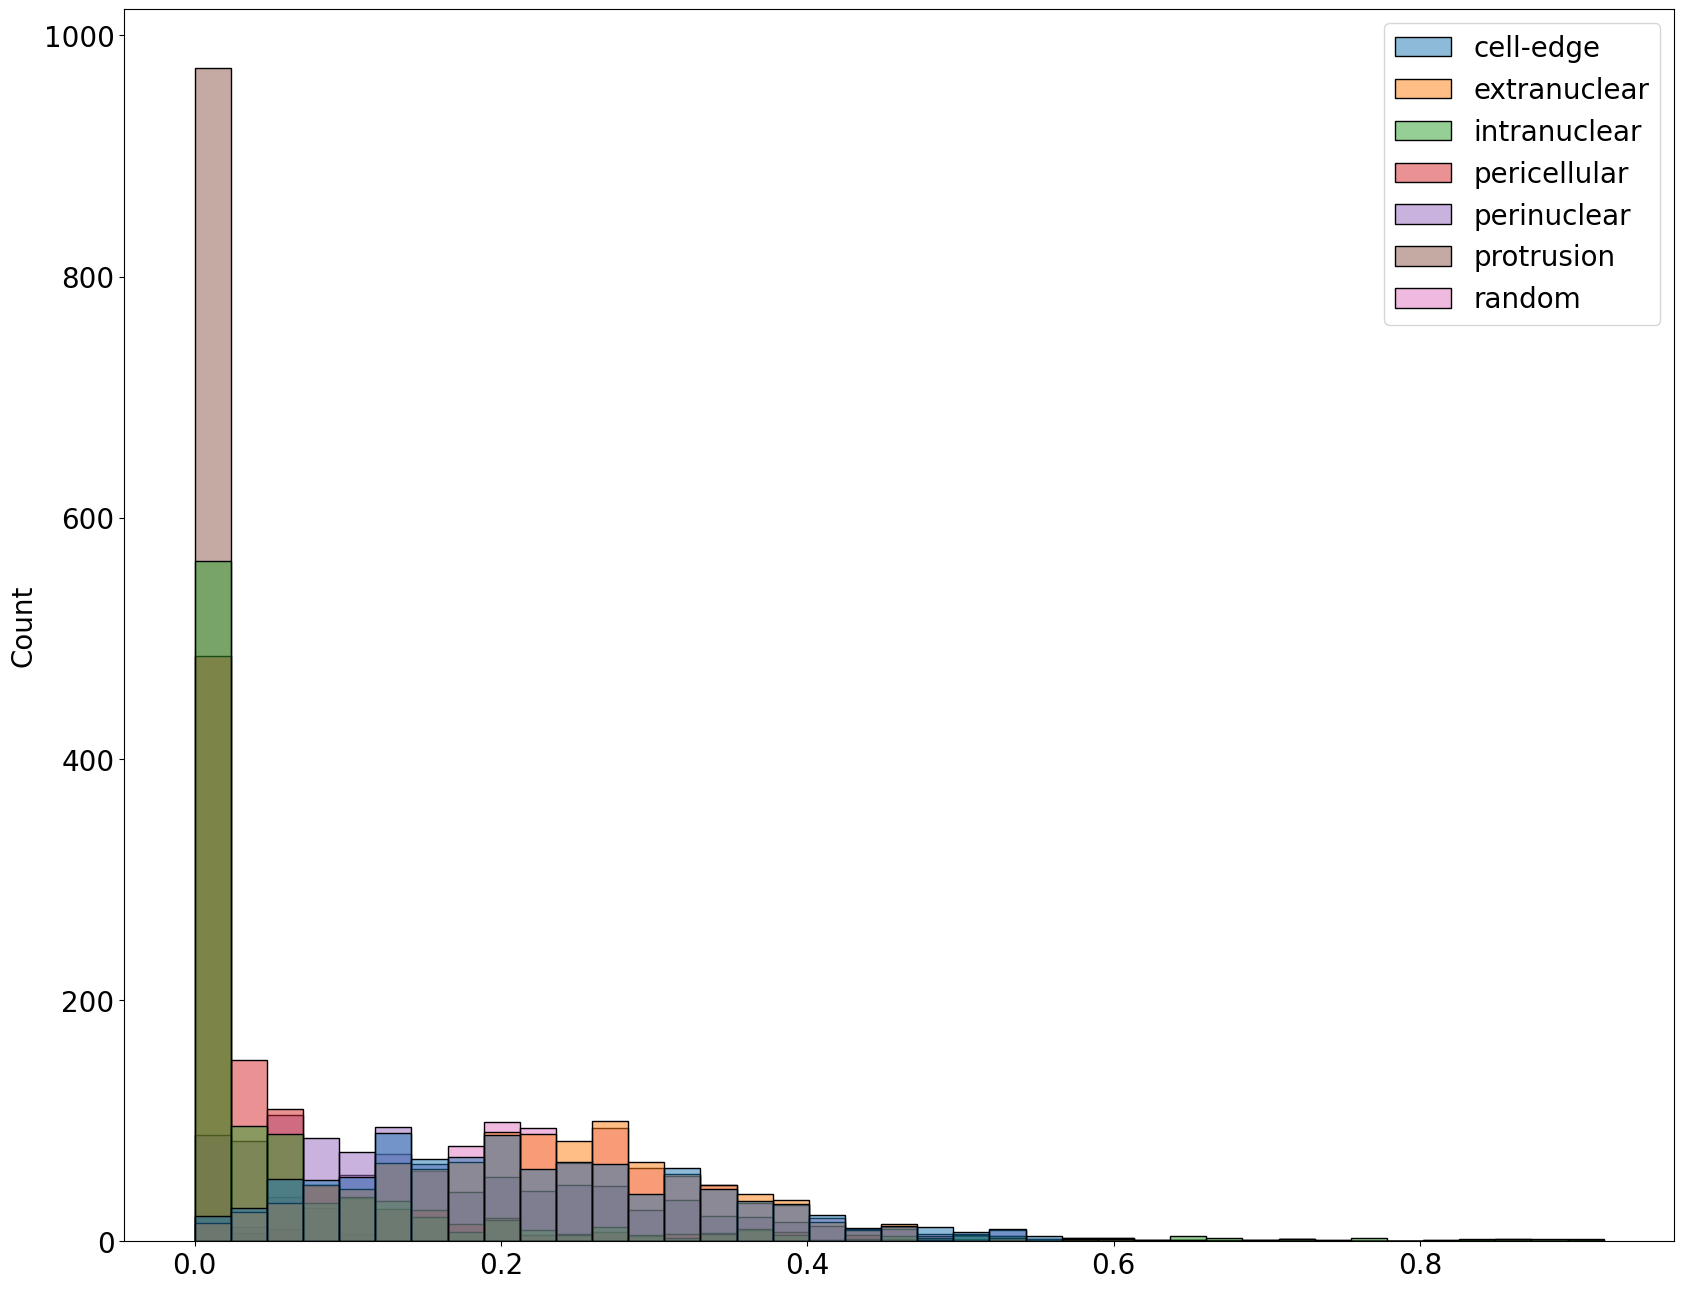

In [462]:
class_scores = multi_classifier.predict_proba(sc.pp.subsample(adata[adata.obs["gene_name"] == "SLC39A10"], n_obs=1000, random_state=seed, copy=True).X)
df = pd.DataFrame(class_scores, columns=multi_classifier.classes_)
sns.histplot(df)

In [193]:
mapping = result_df["subtype_pattern"].to_dict()
adata.obs["subtype_pattern"] = adata.obs["gene_name"].map(mapping)
mapping = result_df["final_class"].to_dict()
adata.obs["final_class"] = adata.obs["gene_name"].map(mapping)

mapping = result_df["apex_assigned"].to_dict()
adata.obs["apex_assigned"] = adata.obs["gene_name"].map(mapping)

In [194]:
result_df["subtype_pattern"].value_counts()

cell-edge       144
extranuclear     66
intranuclear     32
perinuclear      22
Name: subtype_pattern, dtype: int64

In [196]:
result_df["final_class"].value_counts()

random          192
intranuclear     24
cell-edge        22
perinuclear      14
extranuclear     12
Name: final_class, dtype: int64

In [470]:
result_df[cols_of_interest]

,gene_name,true_random,earth_dist,pval,n_obs,bonferonni_pval,subtype_pattern,final_class
AASS,AASS,False,0.039846,1.690722e-05,1000,4.463506e-03,extranuclear,random
ABHD4,ABHD4,False,0.041924,5.256378e-01,27,1.387684e+02,cell-edge,random
ACER3,ACER3,False,0.103109,6.028129e-01,21,1.591426e+02,extranuclear,random
ADAM9,ADAM9,False,0.021734,7.761108e-02,1000,2.048933e+01,extranuclear,random
AGO3,AGO3,False,0.046355,3.270380e-02,333,8.633803e+00,cell-edge,random
...,...,...,...,...,...,...,...,...
ZNF609,ZNF609,False,0.008418,6.101665e-01,1000,1.610839e+02,cell-edge,random
ZNF616,ZNF616,False,0.040050,8.125385e-02,340,2.145102e+01,cell-edge,random
ZNF621,ZNF621,False,0.109837,8.661445e-23,1000,2.286622e-20,cell-edge,cell-edge
ZNHIT3,ZNHIT3,True,0.045791,6.669830e-07,1000,1.760835e-04,cell-edge,random


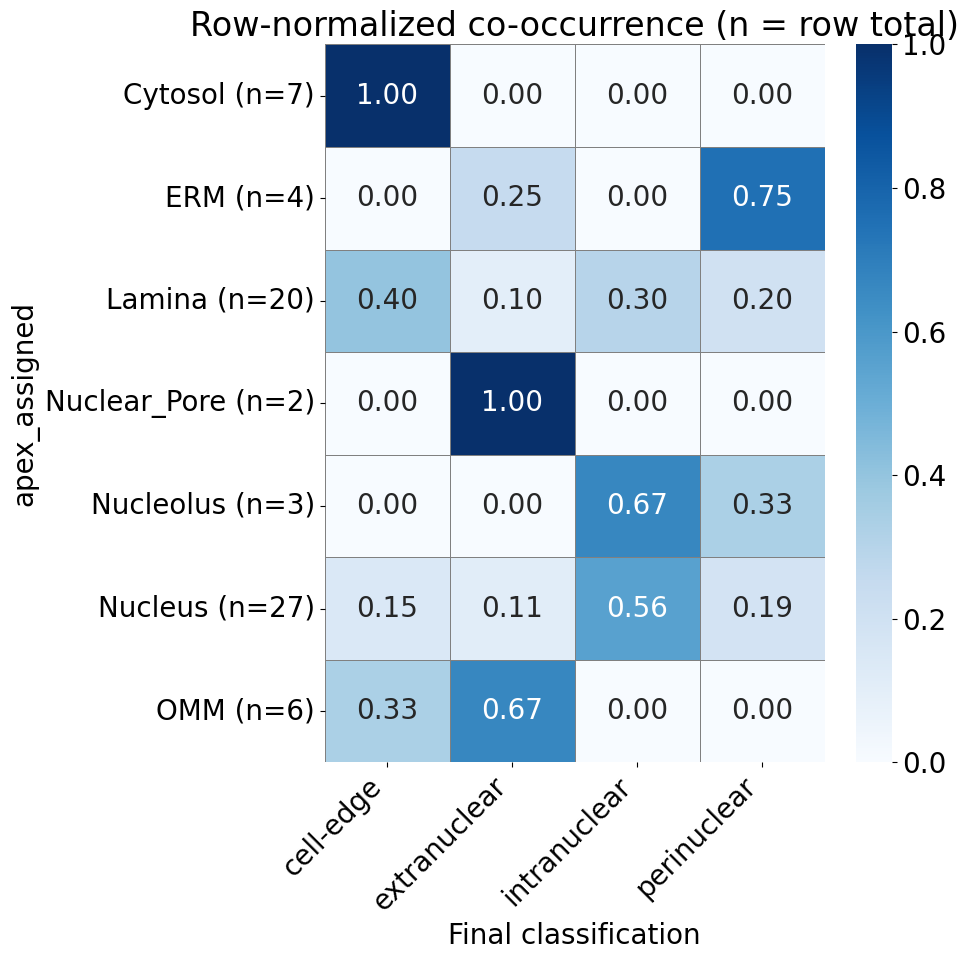

In [471]:
# See if there's global enrichment between the subtypes and a metadata variable
meta_variable = "apex_assigned" # this was our case, yours might be celltype

result_df_that_passes = result_df[result_df["final_class"] != "random"]
result_df_that_passes = result_df_that_passes[result_df_that_passes[meta_variable] != "random"]

ct = pd.crosstab(result_df_that_passes[meta_variable], result_df_that_passes["final_class"])
ct_frac = ct.div(ct.sum(axis=1), axis=0)

# Add counts to y-axis labels
row_counts = ct.sum(axis=1)
y_labels = [f"{idx} (n={row_counts[idx]})" for idx in ct.index]

plt.rcParams["figure.figsize"] = [10,10]
ax = sns.heatmap(
    ct_frac,
    annot=True, fmt=".2f", cmap="Blues",
    cbar=True, linewidths=0.5, linecolor="gray"
)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.set_yticklabels(y_labels, rotation=0)

ax.set_title("Row-normalized co-occurrence (n = row total)")
ax.set_xlabel("Final classification")
ax.set_ylabel(meta_variable)

plt.tight_layout()
plt.show()

# Unsupervised exploration


In [65]:
adjacency = sc._utils._choose_graph(adata, neighbors_key="neighbors",obsp=None)

In [66]:
g = sc._utils.get_igraph_from_adjacency(adjacency)

In [67]:
res = 0.6

In [68]:
clustering = g.community_leiden(objective_function='modularity', resolution_parameter=res,n_iterations=10)


/tmp/ipykernel_2788462/3850926258.py:1: DeprecationWarning: resolution_parameter keyword argument is deprecated, use resolution=... instead
  clustering = g.community_leiden(objective_function='modularity', resolution_parameter=res,n_iterations=10)


In [69]:
adata.obs[f'leiden_igraph_res_{res}'] = pd.Series(clustering.membership,  index=adata.obs.index).astype('category')


In [435]:
sc.tl.umap(adata)

/mnt/data/miniconda3/envs/cvae_david3/lib/python3.8/site-packages/umap/spectral.py:342: UserWarning: Exited at iteration 20 with accuracies 
[0.00821758 0.01918104 0.01904365]
not reaching the requested tolerance 1e-08.
Use iteration 21 instead with accuracy 
0.015480755022685436.

  eigenvalues, eigenvectors = scipy.sparse.linalg.lobpcg(
/mnt/data/miniconda3/envs/cvae_david3/lib/python3.8/site-packages/umap/spectral.py:342: UserWarning: Exited postprocessing with accuracies 
[0.00821758 0.01918104 0.01904365]
not reaching the requested tolerance 1e-08.
  eigenvalues, eigenvectors = scipy.sparse.linalg.lobpcg(


/mnt/data/miniconda3/envs/cvae_david3/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


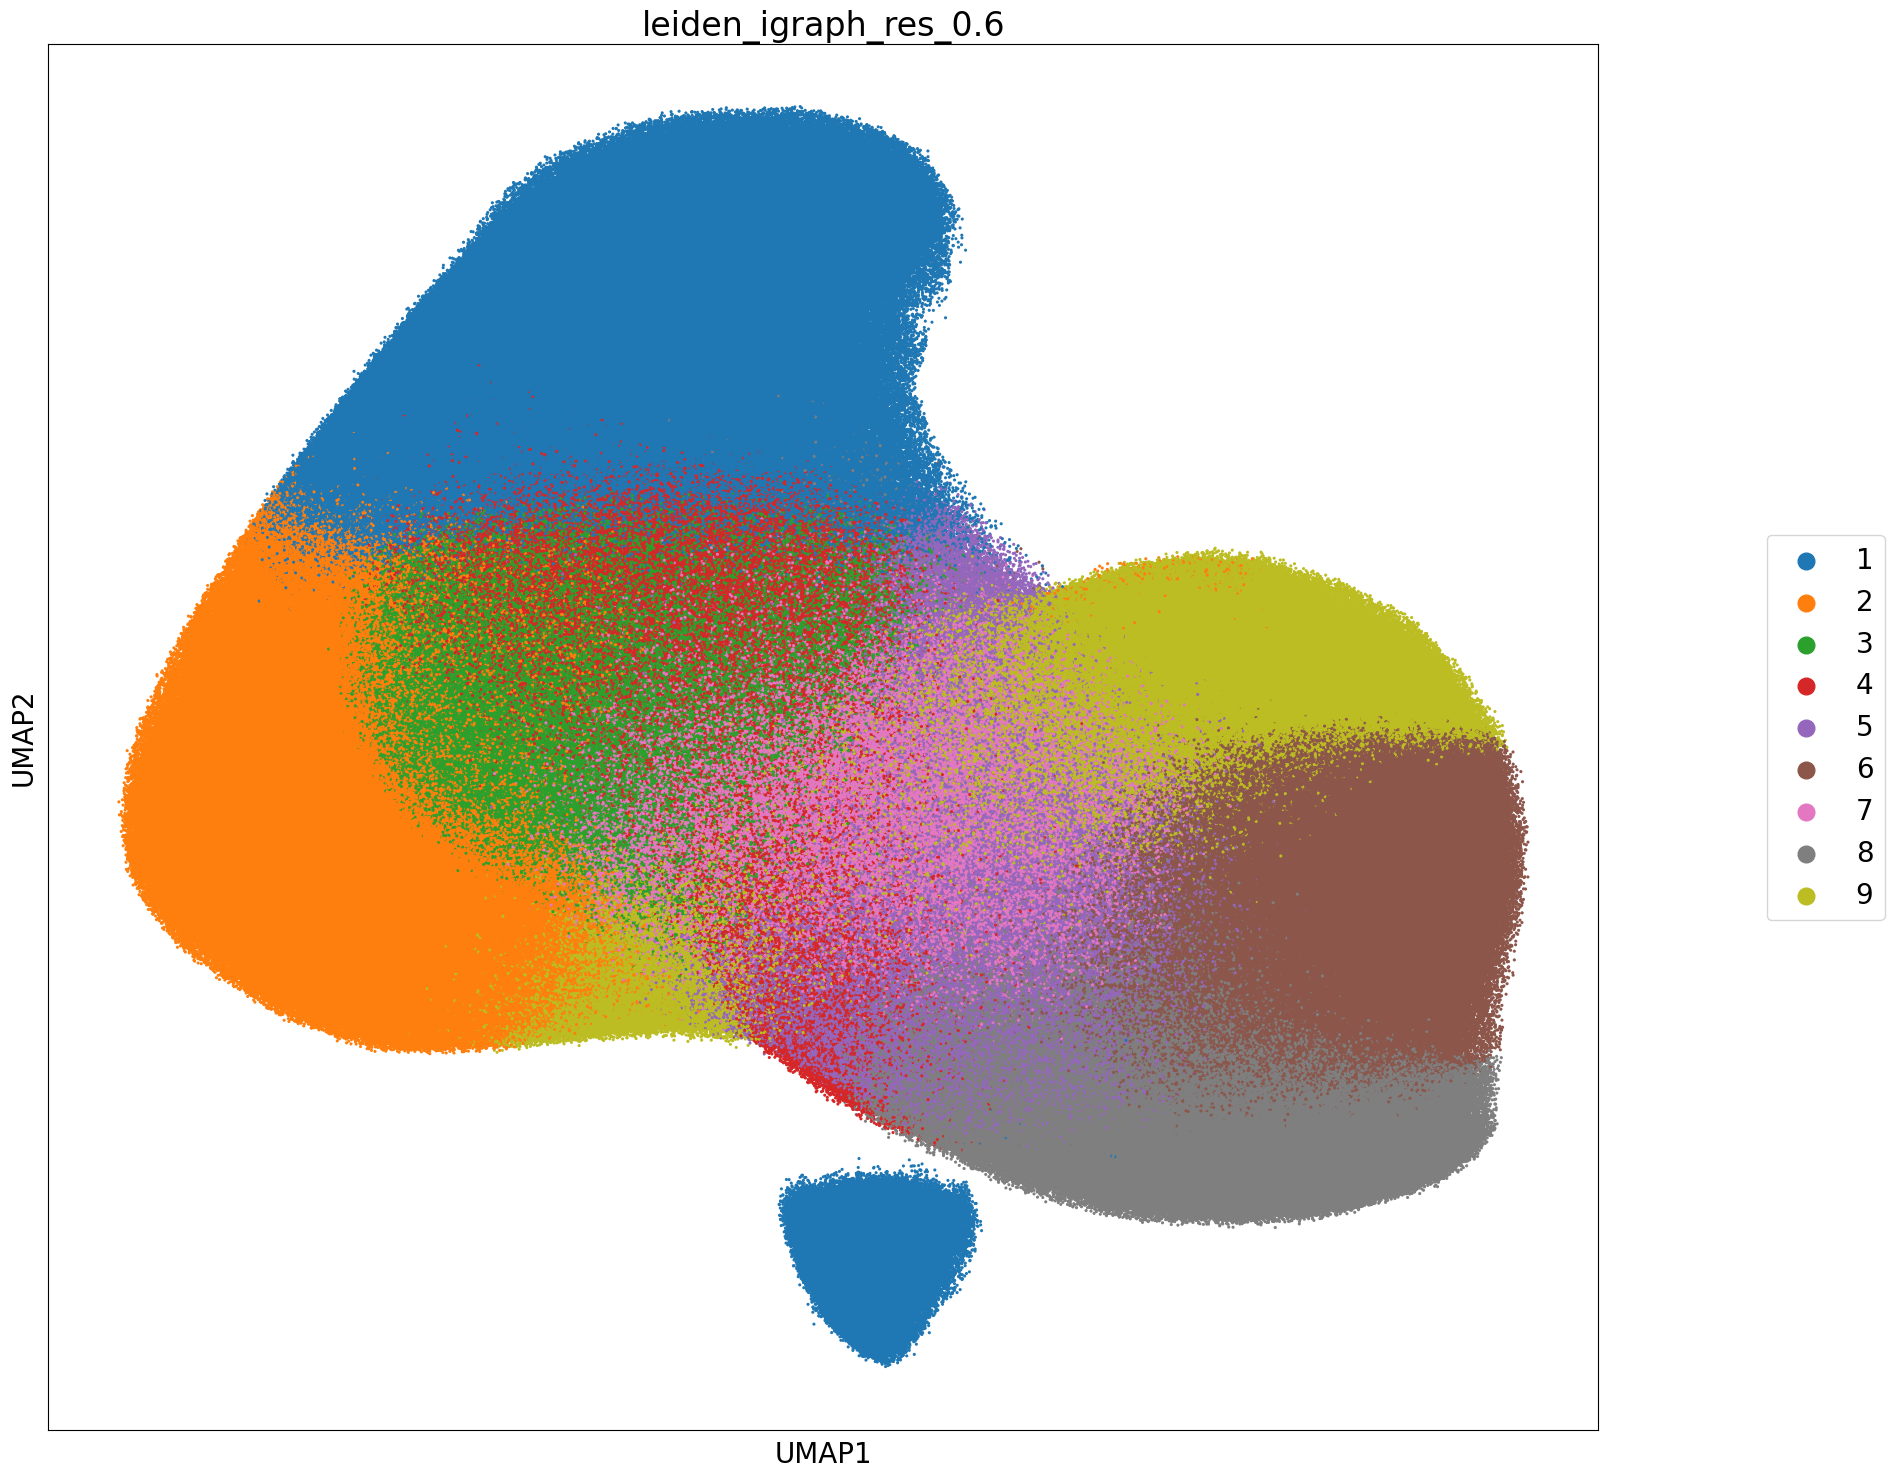

In [92]:
plt.rcParams["figure.figsize"] = [20,18]
fig = sc.pl.umap(adata, color =f'leiden_igraph_res_{res}',s=20, return_fig = True)

## First interpret the clusters with mean decoding:

In [15]:
from skimage.filters import gaussian
plt.rcParams["figure.figsize"] = [16, 10]

def createInputImage(adata_for_one_obs):
    empty = np.zeros((100,100))
    detected_transcripts_for_this_cell = convertRecordToDf(adata_for_one_obs.obsm["detected_transcripts"][0])
    detected_transcripts_for_this_cell_gene = detected_transcripts_for_this_cell[detected_transcripts_for_this_cell["gene"] == adata_for_one_obs.var["gene_name"][0]]
    for tmp_row in detected_transcripts_for_this_cell_gene.itertuples():
        try:
            empty[tmp_row.subcell_row, tmp_row.subcell_col] = 1
        except IndexError:
            empty[tmp_row.subcell_row-1, tmp_row.subcell_col-1] = 1
    gauss = gaussian(empty, 1.5)
    return gauss

def plotAllDataFromLeidenCluster(full_adata, leiden_cluster, ax, leiden_key = "leiden",cell_id = None, model = None, random_seed=seed):
    combined_data_tmp = full_adata[full_adata.obs[leiden_key] == leiden_cluster]
    # If we don't wanna decode, we look at original data
    if model is None:
        # if a cell id is given, we just wanna plot a random observation in a specific cell from this leiden cluster
        if cell_id is not None:
            random.seed(random_seed)
            combined_data_tmp = combined_data_tmp[combined_data_tmp.obs["cell_id"] == str(cell_id)]
            print(f"{leiden_cluster}, {len(combined_data_tmp)} obs in cell available")
            random_gene_in_this_cell_index = random.randint(0, len(combined_data_tmp))

            plotFullDataPoint(single_cell_adata[getXYOfSingleCell(combined_data_tmp, random_gene_in_this_cell_index)], ax=ax)
            ax.set_title(combined_data_tmp.obs["gene_name"].iloc[random_gene_in_this_cell_index] + f" {leiden_cluster}")
            ax.axis("off")
        # if neither model nor cell are given, we just take all input
        else:
            images = []
            for tmp_row in combined_data_tmp:
                input_img = createInputImage(single_cell_adata[tmp_row.obs["original_obs_index"].iloc[0], tmp_row.obs["original_gene_index"].iloc[0]])
                images.append(input_img)
            mean_image = np.mean(np.array(images), axis=0)
            ax.imshow(mean_image)
            ax.set_title(f"cluster {leiden_cluster}, {len(combined_data_tmp)} obs")
            ax.axis("off")
    else:
        midpoint = np.mean(combined_data_tmp.X, axis=0)
        decoded = decodeSubcellEmbedding(midpoint, subcellspace)
        ax.imshow(decoded)
        ax.set_title(leiden_cluster)
        ax.axis("off")

In [98]:
def getCellThatHasObsInEachLeidenCluster(adata, leiden_key = "leiden", return_all = False):
    df = adata.obs
    # Get the unique values in col1
    unique_col1_values = set(df[leiden_key].unique())

    # Group by col2 and find the unique values in col1 for each group
    groups = df.groupby('cell_id')[leiden_key].apply(set).reset_index()

    # Filter the groups where the set of unique values in col1 matches the unique values in the whole col1
    result = groups[groups[leiden_key] == unique_col1_values]

    # Extract the unique value(s) of col2 that satisfy the condition
    unique_values_in_col2 = result['cell_id'].tolist()
    if return_all:
        return unique_values_in_col2
    else:
        return random.sample(unique_values_in_col2, 1)[0]


In [24]:
nr_leiden_clusters = len(adata.obs[f"leiden_igraph_res_{res}"].unique())

/mnt/data/miniconda3/envs/cvae_david3/lib/python3.8/site-packages/numpy/core/fromnumeric.py:3430: RuntimeWarning: Mean of empty slice.
  return mean(axis=axis, dtype=dtype, out=out, **kwargs)
/mnt/data/miniconda3/envs/cvae_david3/lib/python3.8/site-packages/numpy/core/_methods.py:182: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(


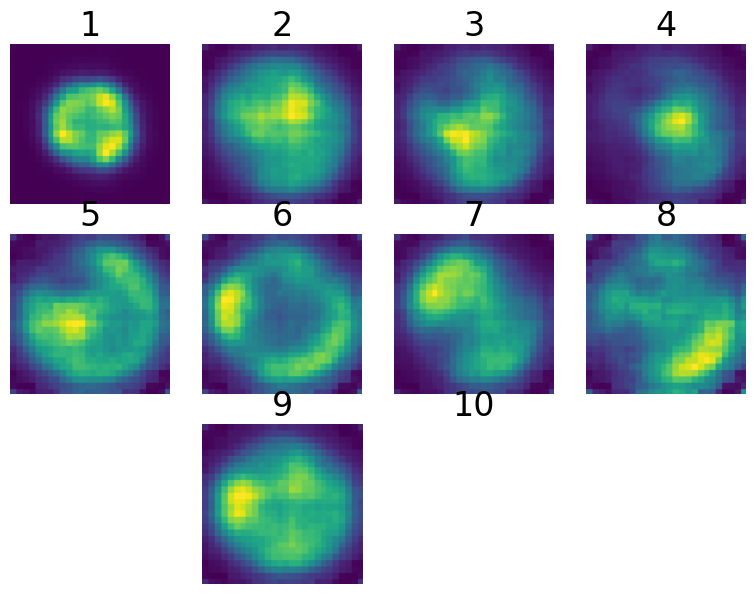

In [38]:
## Take mean of all cluster contents
## Take a cell that has a gene in every cluster and plot it:
%matplotlib inline
nr_leiden_clusters = adata.obs[f"leiden_igraph_res_{res}"].nunique()
fig, axs = get_uneven_subplots(nr_leiden_clusters)
for leid in range(1, nr_leiden_clusters+1):
    plotAllDataFromLeidenCluster(
        full_adata = adata,
        leiden_cluster = leid,
        ax=  axs[leid-1],
        model=subcellspace,
        leiden_key = f"leiden_igraph_res_{res}"
    )

## Then check if there's enrichment between the clusters and metadata

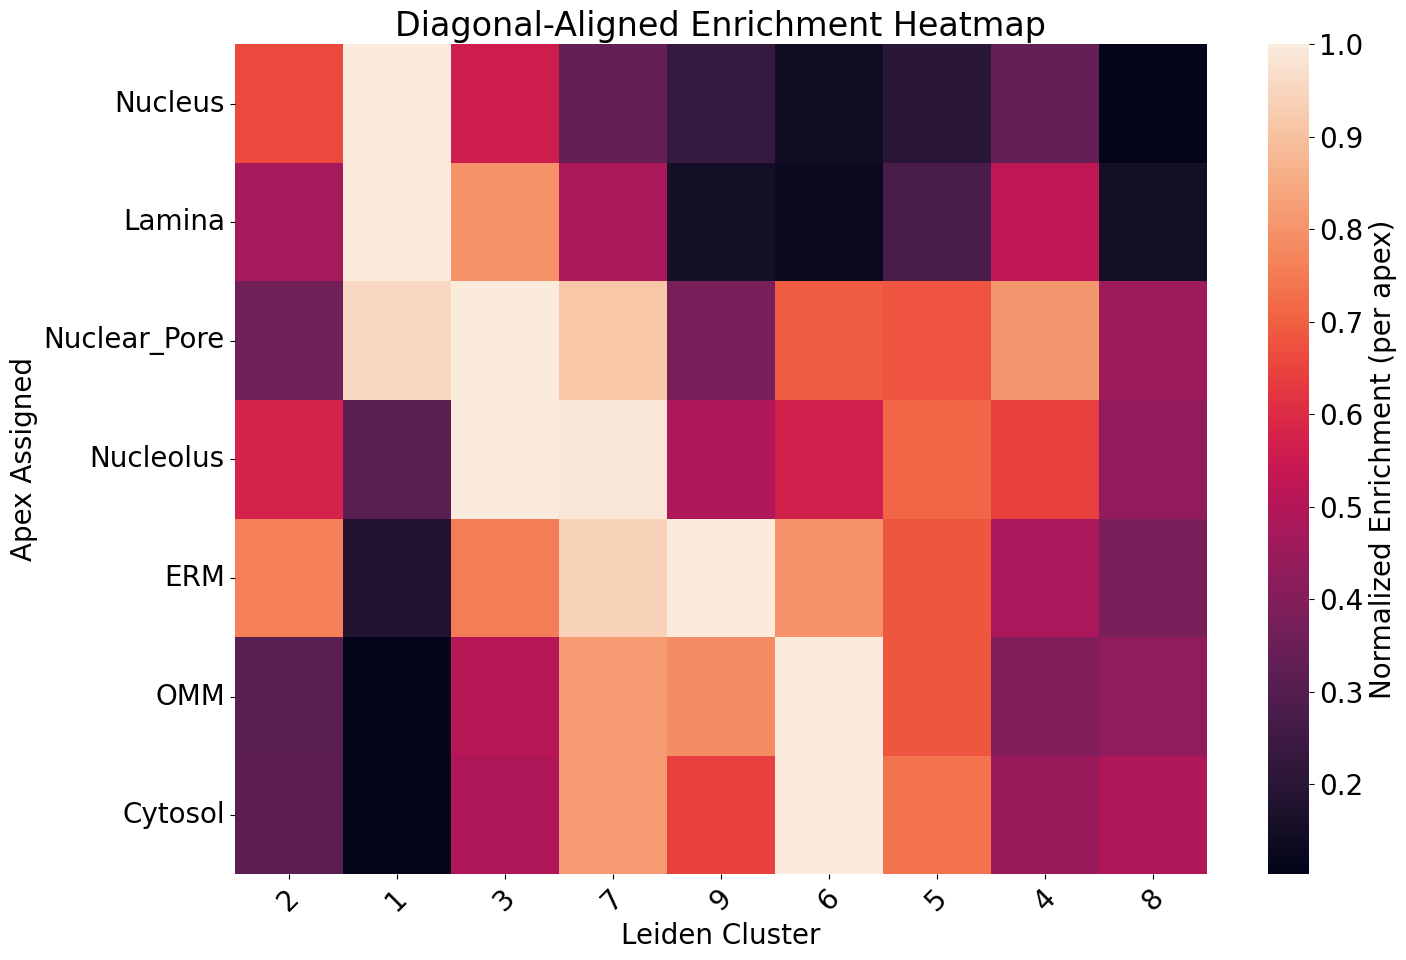

In [45]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import scipy.cluster.hierarchy as sch
import scipy.spatial.distance as ssd
from scipy.optimize import linear_sum_assignment

meta_var = "apex_assigned" # For you it could be celltype for example

obs = adata[adata.obs[meta_var] != "random"].obs[[meta_var, f'leiden_igraph_res_{res}']]

# Aggregate counts
expression_df = pd.crosstab(obs[meta_var], obs[f'leiden_igraph_res_{res}'])


# -----------------------------------------------------------
# 1️⃣ Row clustering (with optimal ordering)
# -----------------------------------------------------------
row_dist = ssd.pdist(expression_df.values, metric="euclidean")
row_linkage = sch.linkage(row_dist, method="ward")
row_linkage = sch.optimal_leaf_ordering(row_linkage, row_dist)

row_order = sch.leaves_list(row_linkage)

# Reorder rows
df_row_ordered = expression_df.iloc[row_order]

# -----------------------------------------------------------
# 2️⃣ Hungarian matching (align columns to rows)
# -----------------------------------------------------------
cost_matrix = -df_row_ordered.values  # maximize diagonal

row_ind, col_ind = linear_sum_assignment(cost_matrix)

matched_cols = list(col_ind)

# -----------------------------------------------------------
# 3️⃣ Keep ALL columns (append unmatched ones)
# -----------------------------------------------------------
all_cols = list(range(df_row_ordered.shape[1]))
unmatched_cols = [c for c in all_cols if c not in matched_cols]

# Optional: cluster unmatched columns for nicer ordering
if len(unmatched_cols) > 1:
    extra = df_row_ordered.iloc[:, unmatched_cols]
    col_dist_extra = ssd.pdist(extra.T, metric="euclidean")
    col_linkage_extra = sch.linkage(col_dist_extra, method="ward")
    col_order_extra = sch.leaves_list(col_linkage_extra)
    unmatched_cols = [unmatched_cols[i] for i in col_order_extra]

# Final column order: diagonal first, then remaining columns
col_order = matched_cols + unmatched_cols

# Apply final ordering
ordered_df = df_row_ordered.iloc[:, col_order]

# -----------------------------------------------------------
# 4️⃣ Plot heatmap
# -----------------------------------------------------------
fig, ax = plt.subplots(figsize=(15,10))

sns.heatmap(
    ordered_df,
    robust=True,
    ax=ax,
    cbar_kws={"label": "Normalized Enrichment (per apex)"},
)

ax.set_xlabel("Leiden Cluster")
ax.set_ylabel(meta_var)
ax.set_title("Diagonal-Aligned Enrichment Heatmap")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

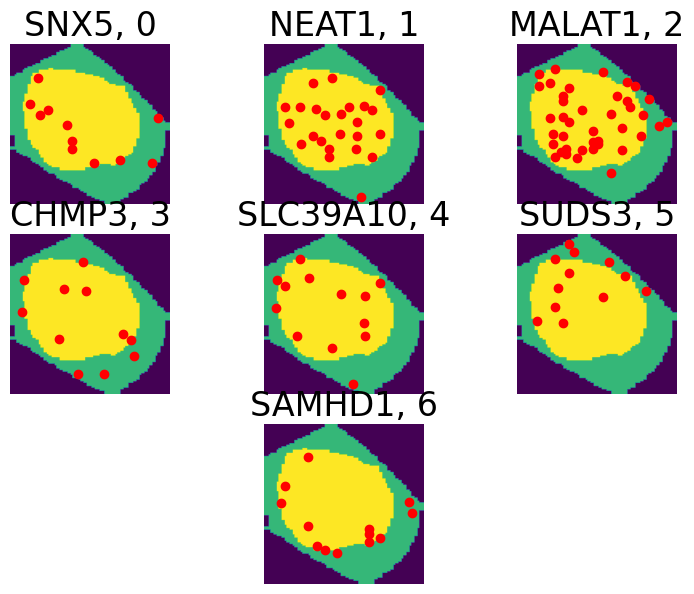

In [738]:
## Take a cell that has a gene in every cluster and plot it:
%matplotlib inline
nr_leiden_clusters = adata.obs[f"leiden_igraph_res_{res}"].nunique()
fig, axs = create_custom_grid(nr_leiden_clusters)
random_cell_id = getCellThatHasObsInEachLeidenCluster(adata, leiden_key = f"leiden_igraph_res_{res}")
for leid in range(nr_leiden_clusters):
    plotAllDataFromLeidenCluster(
        full_adata = adata,
        leiden_cluster = leid,
        ax=  axs[leid],
        cell_id = random_cell_id,
        leiden_key = f"leiden_igraph_res_{res}",
    )

# Unsupervised: check if there are correlated or segregated gene-pairs

In [124]:
from sklearn.metrics.pairwise import cosine_similarity,euclidean_distances
import ot

In [125]:
def calculate_cosine_similarity(matrix1, matrix2):
    M = ot.dist(matrix1, matrix2, metric="cosine")
    return np.mean(M)

In [214]:
def plot_genes_side_by_side(adata, gene1, gene2, cell_id=None, ax=None, color1="red", color2="blue", size= 10):
    if ax is None:
        fig, ax = plt.subplots(1,1)
        
    genes = adata.obs["gene_name"]
    
    cell_ids = adata.obs["cell_id"]
    
    for index, (tmp_gene, tmp_cell_id) in enumerate(zip(genes,cell_ids)):
        if tmp_gene == gene1 and tmp_cell_id == cell_id:
            matching_index1 = index

        if tmp_gene == gene2 and tmp_cell_id == cell_id:
            matching_index2 = index
    
    
    plotFullDataPoint(single_cell_adata[getXYOfSingleCell(adata, matching_index1)], ax = ax, color=color1, size=size)
    plotFullDataPoint(single_cell_adata[getXYOfSingleCell(adata, matching_index2)], ax = ax, color=color2, size=size)
    return matching_index1, matching_index2


In [135]:
# Calculate all gene-pair distances (not optimized, could take a while)
bidirectional_dict_gene_pair_dict = {}

cell_id_counts = adata.obs["cell_id"].value_counts()
for cell_id, count in tqdm(cell_id_counts.items(), total = len(cell_id_counts)):
    if count > 1:
        cell_specific_real_pattern_adata = adata[adata.obs["cell_id"]==cell_id]
        genes_in_this_cell = list(cell_specific_real_pattern_adata.obs["gene_name"].unique())
        for i, gene1 in enumerate(genes_in_this_cell):
            for gene2 in genes_in_this_cell[i+1:]:
                pair_key = tuple(sorted((gene1, gene2)))
                gene1_arr = np.array(cell_specific_real_pattern_adata[cell_specific_real_pattern_adata.obs["gene_name"] == gene1].X)
                gene2_arr = np.array(cell_specific_real_pattern_adata[cell_specific_real_pattern_adata.obs["gene_name"] == gene2].X)
                
                similarity = calculate_cosine_similarity(gene1_arr, gene2_arr)
                
                if pair_key in bidirectional_dict_gene_pair_dict:
                    bidirectional_dict_gene_pair_dict[pair_key].append(similarity)
                else:
                    bidirectional_dict_gene_pair_dict[pair_key] = [similarity]



100%|████████████████████████████████████████████████████████████████████████████████████████████████| 407/407 [01:01<00:00,  6.62it/s]


In [136]:
# select those that have 4 or more matches
list_of_gene_pairs_and_their_mean_values = []
for k, v in bidirectional_dict_gene_pair_dict.items():
    if len(v) > 4:
        list_of_gene_pairs_and_their_mean_values.append((k[0], k[1], np.mean(v), len(v)))
    

In [196]:
# Sort em
sorted_list_of_gene_pairs_and_their_mean_values = sorted(list_of_gene_pairs_and_their_mean_values, key=lambda x: x[2], reverse=False)

top_n_similar_pairs = sorted_list_of_gene_pairs_and_their_mean_values

for i, pair in enumerate(top_n_similar_pairs):
    gene1, gene2, similarity, n_observations = pair
    print(f"{i}: {gene1}-{gene2} have a distance of {similarity} with {n_observations} observations")

0: Fos-Uqcrfs1 have a distance of 0.02735297696979431 with 5 observations
1: Aoc1-Clca4b have a distance of 0.03869889166178037 with 187 observations
2: Nlrp6-Serinc3 have a distance of 0.03918656294084636 with 6 observations
3: Aoc1-Apob have a distance of 0.04299480825321351 with 274 observations
4: Dpp4-Fos have a distance of 0.04705549881697172 with 7 observations
5: Irf1-Serinc3 have a distance of 0.04732901156936478 with 17 observations
6: Hnf4a-Nlrp6 have a distance of 0.04743904693255754 with 22 observations
7: Nlrp6-Uqcrfs1 have a distance of 0.047940787594105395 with 9 observations
8: Ceacam1-Fat1 have a distance of 0.04831057885188688 with 9 observations
9: Apob-Clca4b have a distance of 0.048728725401225234 with 204 observations
10: Ctnnb1-Eif4h have a distance of 0.04884551930823361 with 17 observations
11: Eif4h-Nlrp6 have a distance of 0.04979770167073315 with 21 observations
12: Aoc1-Cdh1 have a distance of 0.04999200931110517 with 8 observations
13: Eif4h-Uqcrfs1 have 

In [ ]:
# plot em
gene1, gene2, similarity, n_observations = top_n_similar_pairs[0]
plot_genes_side_by_side(adata, gene1, gene2, cell_id=None, ax=None, color1="red", color2="blue", size= 10):


## Now the experimental functionality: clicking on the latent space

In [1051]:
from scipy import spatial

plotted_point = None
def checkInputScanpyPlot(plot_adata, adata, color, metadata,  axs = None, f = None, ax0_title="", size=2):
    '''
    All data argument is just so that we can plot just a subset, but find the closest label in the entire dataset
    '''
    #     global pos
    def findSecondClosestDot(adata, point, tree):
        closest_neighbor_index = tree.query([point], k=2)[1][0][0] # last indexing is which closest neighbor to take
        return closest_neighbor_index
        
    coord_list = []
    for row in adata.obsm["X_umap"]:
        coord_list.append(tuple(row))
    tree = spatial.KDTree(coord_list)
    
    
    if (axs == None) and (f == None):
        f,axs = plt.subplots(1,2)
        
    sc.pl.umap(plot_adata, color=color, show=False, legend_fontsize=10, title="", size=size, ax=axs[0])
#     print([f"{meta}: {adata.obs[meta][0]}" for meta in metadata].join(' '))

    axs[0].set_title(ax0_title)
    for ax in axs:
        ax.axis("off")
        
     
    def onclick(event):
        axs[1].clear()
        pos = (event.xdata,event.ydata)

        index = tree.query([pos])[1][0]
        axs[0].set_title(index)
        plotFullDataPoint(single_cell_adata[getXYOfSingleCell(adata, index)], ax=axs[1])
        meta_list = [f"{meta}: {adata.obs[meta][index]}" for meta in metadata]
        axs[1].set_title(' '.join(meta_list))
        axs[1].axis("off")
        axs[1].draw()

    f.canvas.mpl_connect('button_press_event', onclick)
    f.show()
    

<IPython.core.display.Javascript object>


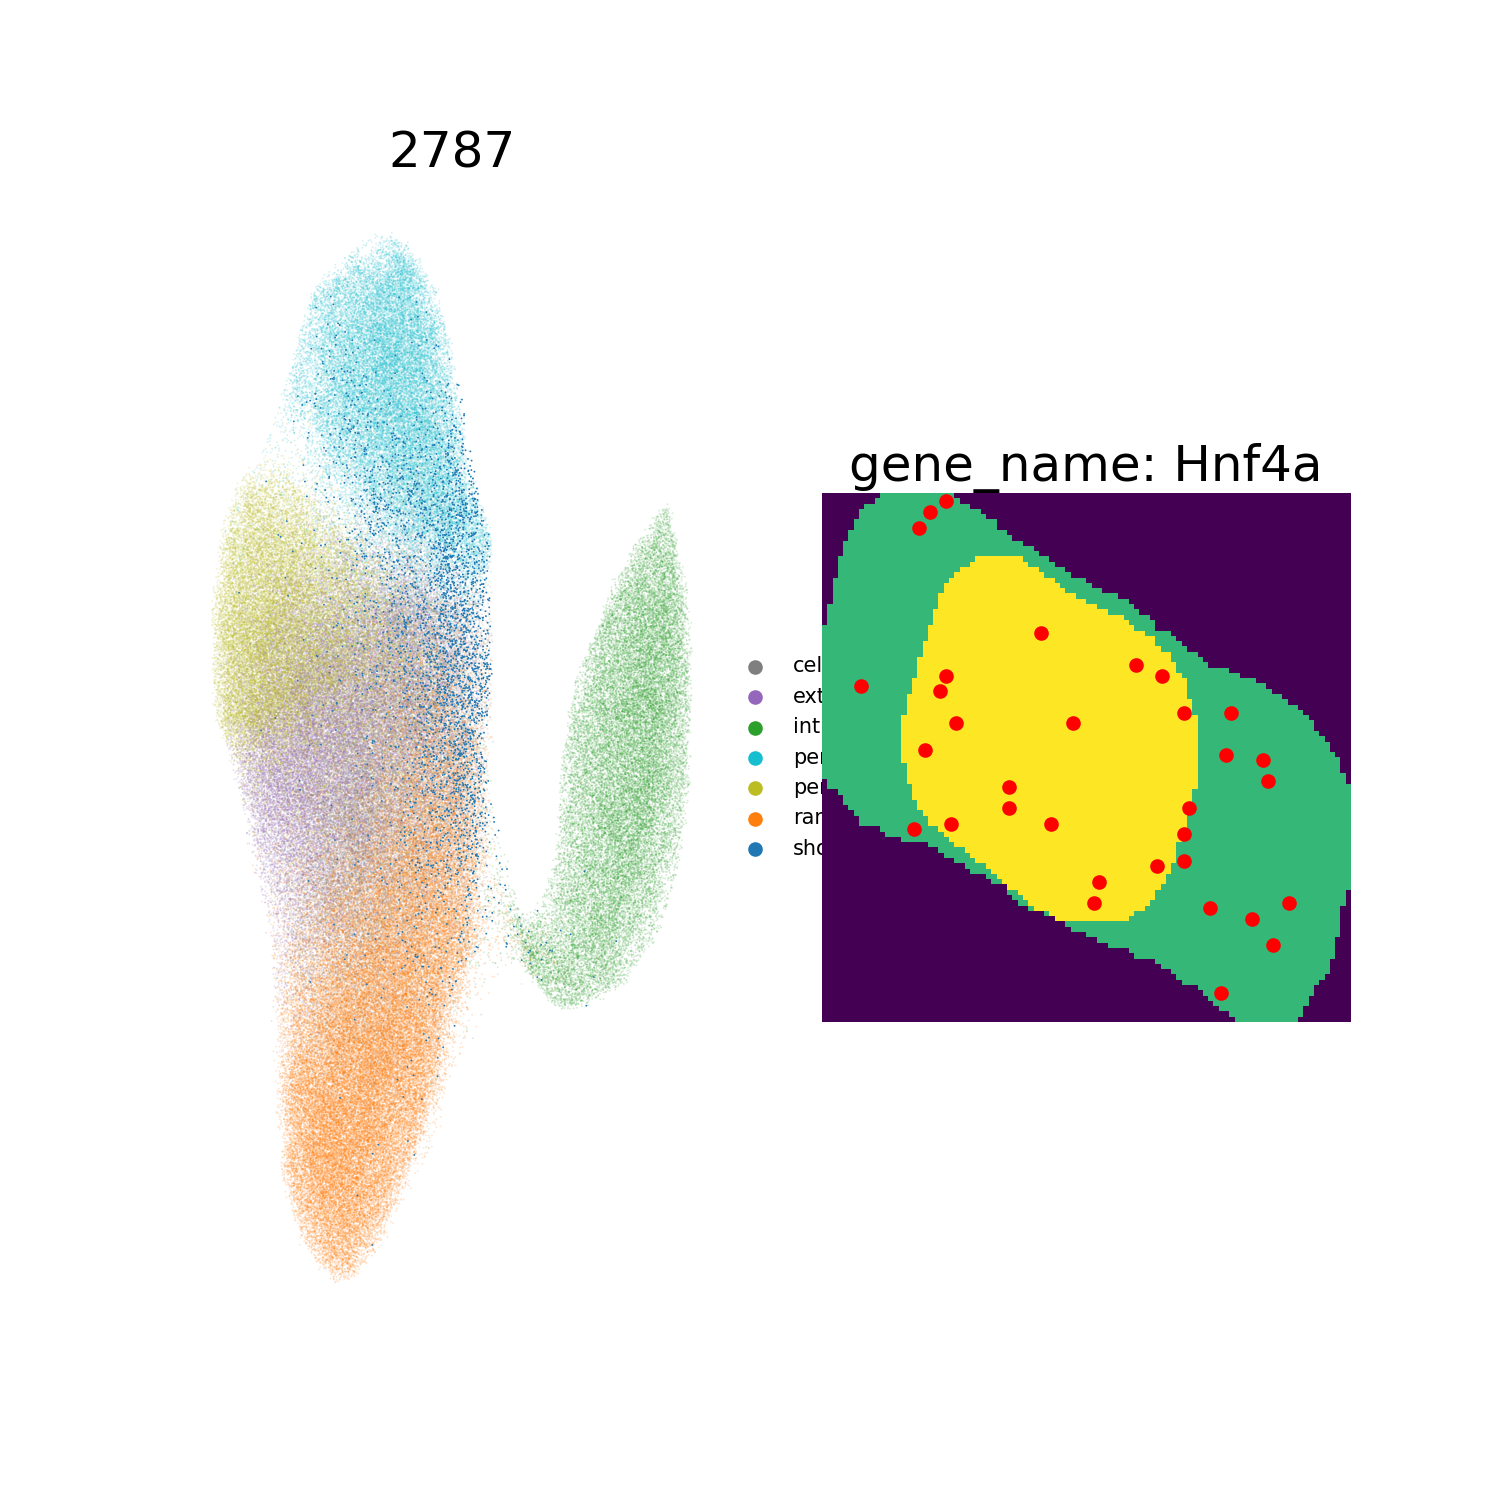

/mnt/data/miniconda3/envs/cvae_david3/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


In [293]:
%matplotlib notebook
plt.rcParams["figure.figsize"] = [10,10]

checkInputScanpyPlot(adata,
                    adata[adata.obs["final_class"] != "random"],
                     color="pattern", 
                        metadata=["gene_name"], 
                        size=3,
                    )


## Even more experimental: Draw a pattern and find closest match

In [16]:
%matplotlib inline
adata.obs["cell_id"].value_counts()

NameError: name 'adata' is not defined

In [882]:
# take cell with highest obs
cell_id = "tile26_row3139_col3462_1746_corrID_1774"
dapi = single_cell_adata[single_cell_adata.obs["cell_id"] == cell_id].obsm["dapi_mask"][0].reshape(100,100)
cell = single_cell_adata[single_cell_adata.obs["cell_id"] == cell_id].obsm["cell_mask"][0].reshape(100,100)

In [527]:
def create_new_input(adata_row):
    dapi = adata_row.obsm["dapi_mask"][0].reshape((100,100))
    cell = adata_row.obsm["cell_mask"][0].reshape((100,100))
    
    gene_expression_img = np.zeros(dapi.shape)
    for col, tmp_row in clicked_points:
            copy[int(tmp_row), int(col)] = 1
    gauss = gaussian(copy,1.5)

<IPython.core.display.Javascript object>


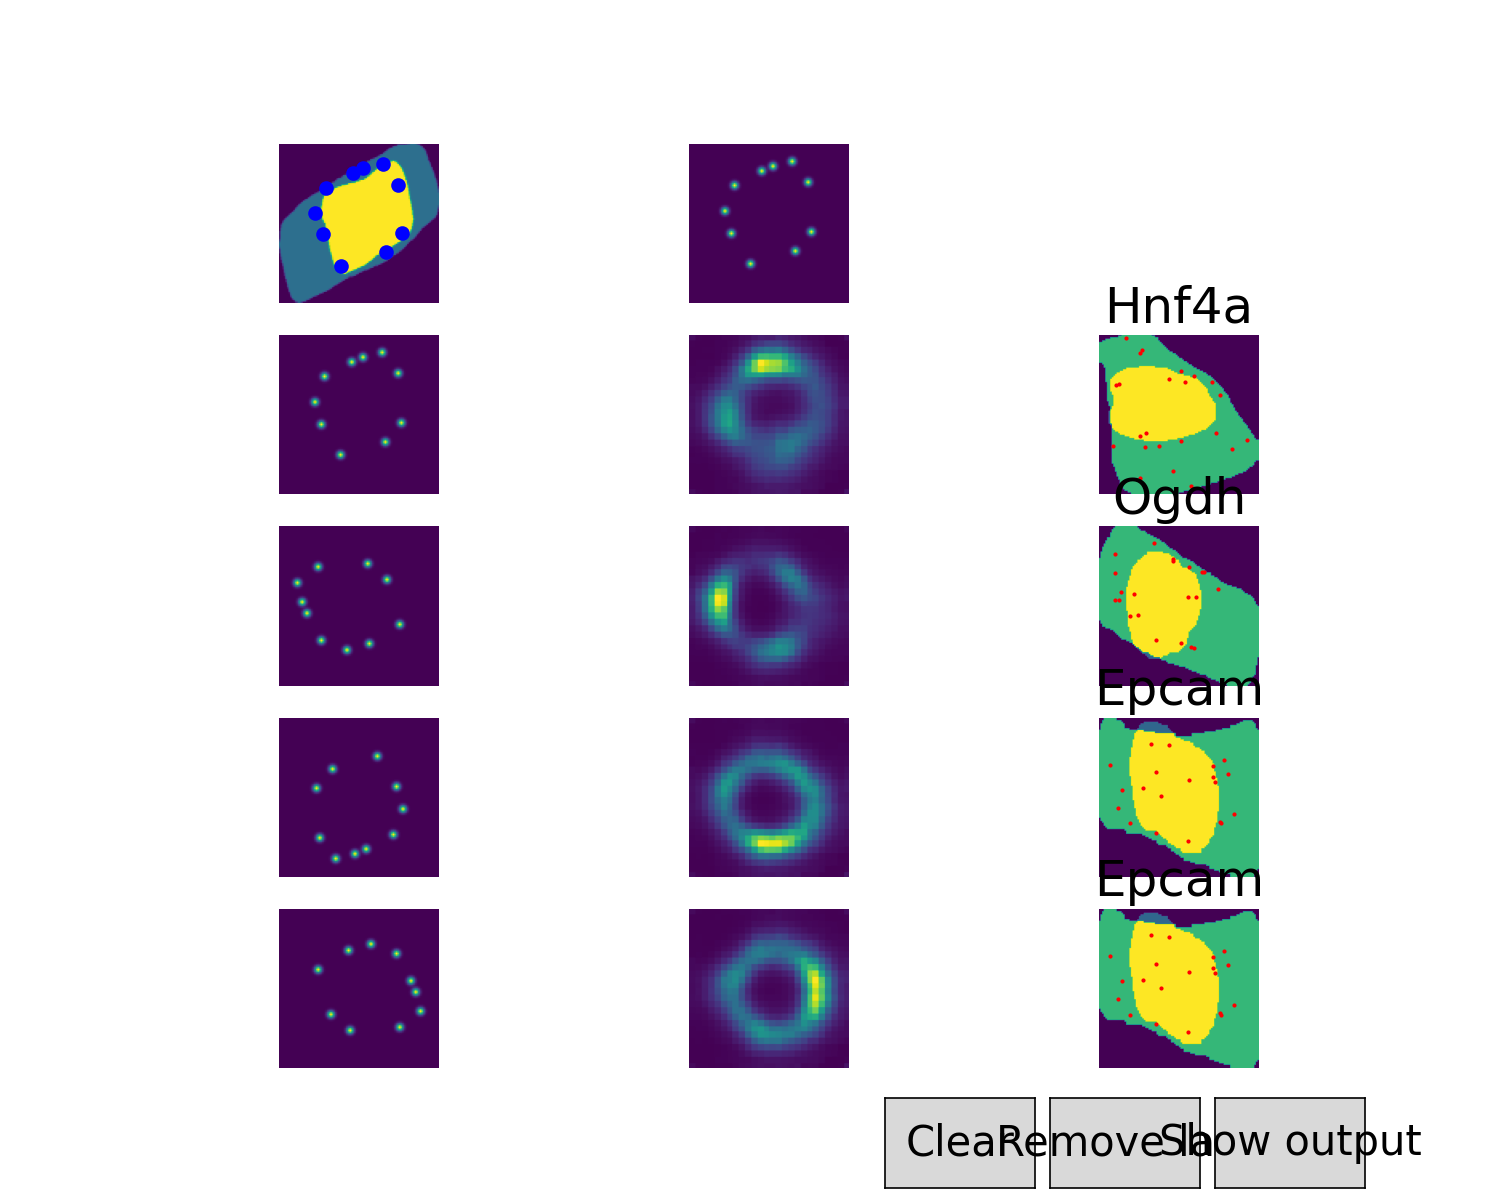

In [959]:
%matplotlib notebook
from skimage.transform import rotate
def drawAPatternAndRotate(dapi, cell, model, adata=None):
    
    if adata is not None:
        fig, axs = plt.subplots(5,3, sharex=True, sharey=True)
        
        coord_list = []
        for tmp_row in adata.X:
            coord_list.append(tuple(tmp_row))
        tree = spatial.KDTree(coord_list)
        
    else:
        fig, axs = plt.subplots(1,3, sharex=True, sharey=True)
        
#     axs = axs.flatten()
    axs[0,0].imshow(dapi + cell)
    axs[0,1].imshow(dapi + cell)
    
    gene_expression_img = np.zeros(dapi.shape)
    for ax in axs.flatten():
        ax.axis("off")
    
    clicked_points = []
    plotted_points = []
    
    def plotOutput():
        copy = np.zeros(dapi.shape)
        for col, tmp_row in clicked_points:
            copy[int(tmp_row), int(col)] = 1
        gauss = gaussian(copy,1.5)
        axs[0,1].imshow(gauss + dapi + cell)
        
        all_imgs_to_do = [rotate(gauss, angle) for angle in (0, 90, 180, 270)]
        all_dapi_to_do = [rotate(dapi, angle) for angle in (0, 90, 180, 270)]
        all_cells_to_do = [rotate(cell, angle) for angle in (0, 90, 180, 270)]
        for i, (tmp_gauss, tmp_dapi, tmp_cell) in enumerate(zip(all_imgs_to_do, all_dapi_to_do, all_cells_to_do), 1):
            axs[i, 0].imshow(tmp_gauss + tmp_dapi + tmp_cell)
            gene_expression = model["cvae"].prepare_new_input(tmp_gauss)
            dapi_prepared = model["cvae"].prepare_new_input(tmp_dapi)

            input_img = torch.cat((gene_expression, dapi_prepared), dim=1)

            model["cvae"].to(model['device'])
            input_img = input_img.to(model['device'])
            reconstruction, _, _ = model['cvae'].forward(input_img)
            axs[i, 1].imshow(np.array(reconstruction[0,0,:,:].detach().to("cpu")))

            if adata is not None:
                embedding, _, _ = model["cvae"].embed(input_img)
                index = tree.query([embedding.detach().cpu().squeeze(dim=0).numpy()])[1][0]
                plotFullDataPoint(single_cell_adata[getXYOfSingleCell(adata, index)], ax=axs[i,2], size=1)
                axs[i,2].set_title(adata.obs["gene_name"][index])
        
        
    def removeLast():
        clicked_points.pop()
        point_to_remove = plotted_points.pop()
        point_to_remove.remove()
        
    def clear():
        axs[0].clear()
        
        # Use del instead of overwriting the variables cause they're global variables
        del clicked_points[:]
        del plotted_points[:]

        axs[0].imshow(dapi + cell)
        axs[1].imshow(dapi + cell)
        
    def onclick(event):
        if event.inaxes in axs.flatten():
            pos = (event.xdata,event.ydata)
            clicked_points.append(pos)
            plotted_points.append(axs[0, 0].plot(pos[0], pos[1], 'bo')[0])
        elif event.inaxes == axprev:
            removeLast()
        elif event.inaxes == axoutput:
            plotOutput()
        elif event.inaxes == axclear:
            clear()



    fig.canvas.mpl_connect('button_press_event', onclick)
    
    axclear = fig.add_axes([0.59, 0.01, 0.1, 0.075])
    axprev = fig.add_axes([0.7, 0.01, 0.1, 0.075])
    axoutput = fig.add_axes([0.81, 0.01, 0.1, 0.075])
    
    bclear = Button(axclear, 'Clear')
    boutput = Button(axoutput, 'Show output')
    boutput.on_clicked(plotOutput)
    
    bprev = Button(axprev, 'Remove last')
    bprev.on_clicked(removeLast)
    fig.show()
    return fig
    
fig = drawAPatternAndRotate(dapi,cell, blurry, adata) 